# Figure 1: A transcriptional pre-screen of 240 developmental TFs
### Loading 240 TF RNA dataset
Reading in the 240 TF primary screen data as Monocle3 object, and converting it to a Seurat object.

The following dataset:

`RNA-240.monocle3.rds`

corresponds to:

`GSE353547_Screen240TF_scRNA_mESC_monocle3_cds.rds`

In [1]:
# Loading in packages and useful functions (e.g. lochNESS)
source("./load_packages.R")

# Converting dataset from Monocle3 object to a Seurat object
rna.240 <- readRDS("../data/RNA-240.monocle3.rds")
count = exprs(rna.240)

rownames(count) <- rownames(rna.240)
colnames(count) <- colnames(rna.240)

pd = data.frame(pData(rna.240))
rna.obj = CreateSeuratObject(count, meta.data = pd)
rna.obj = NormalizeData(rna.obj, normalization.method = "LogNormalize", scale.factor = 10000)
rna.obj@meta.data$gRNAs <- ifelse(is.na(rna.obj@meta.data$gRNAs), "", rna.obj@meta.data$gRNAs)
rna.obj@meta.data$target <- ifelse(is.na(rna.obj@meta.data$target), "", rna.obj@meta.data$target)

# adding the umap
umap.mat <- reducedDims(rna.240)$UMAP
rna.obj[["umapRNA"]] <- CreateDimReducObject(embeddings = umap.mat, key = 'umapRNA_', assay = DefaultAssay(rna.obj))
# adding the pca
pca.mat <- reducedDims(rna.240)$PCA
rna.obj[['pca']] <- CreateDimReducObject(embeddings = pca.mat, key = 'pca_', assay = DefaultAssay(rna.obj))

kadj = round(0.5 * sqrt(ncol(rna.obj)))

rna.obj = rna.obj %>%Seurat::L2Dim(reduction='pca')%>%
  Seurat::FindNeighbors(reduction='pca.l2', dims=1:50, k=kadj)


meta <- as.data.frame(rna.obj@meta.data)
meta$n.guides <- str_count(meta$gRNAs, "_") + 1
meta$n.guides[is.na(meta$n.guides)] <- 0

# Getting a list of the 240 TFs in the RNA screen
rna.targets <- sort(unique(meta[meta$n.guides == 1 & meta$target != "NTC",]$target))
rna.targets <- rna.targets[ !(rna.targets %in% c('Hnf4g','Myf5'))]

Registered S3 method overwritten by 'eulerr':
  method    from  
  plot.venn gplots


Attaching package: 'eulerr'


The following object is masked from 'package:gplots':

    venn


Normalizing layer: counts

Warning message:
"No columnames present in cell embeddings, setting to 'umapRNA_1:3'"
Computing nearest neighbor graph

Computing SNN



### Figure 1A: Schematic experimental overview
### Figure 1B: Target activation volcano plot
Volcano plot to show that gRNA cells have higher expression of the corresponding target TF for most targets. First, reading in a dataframe that has the DEGs for each target TF (found using Seurat's find and using all cells with a gRNA for a given TF as "ident.1" and cells assigned a NTC gRNA as "ident.2"):

In [2]:
degs <- as.data.frame(matrix(ncol=0,nrow=0))
targets <- c(rna.targets[2:length(rna.targets)],"NTC")
for (tf in targets) {
    message(tf)
    tf.cells <- rownames(rna.obj@meta.data[grepl(tf,rna.obj@meta.data$target) == TRUE,])
    rna.obj@meta.data$group <- ifelse(grepl(tf,rna.obj@meta.data$target) == TRUE,tf,
                               ifelse(rna.obj@meta.data$target == "NTC","NTC","other"))
    
    Idents(rna.obj) <- rna.obj@meta.data$group
    
    if (tf != "NTC") {
      tf_de <- FindMarkers(rna.obj,
                           ident.1 = tf,
                           ident.2 = "NTC",
                           logfc.threshold = 0,
                           min.pct         = 0)
    } else if (tf == "NTC") {
      tf_de <- FindMarkers(rna.obj,
                           ident.1 = tf,
                           ident.2 = "other",
                           logfc.threshold = 0,
                           min.pct         = 0)
    }
    
    tf_de$target <- tf
    tf_de$gene <- rownames(tf_de)
    rownames(tf_de) <- paste0(tf,":",tf_de$gene)
    degs <- rbind(degs,tf_de)
    
}

saveRDS(degs,"../data/rna-240_all-degs.rds")

Alx1

Alx3

Alx4

Ar

Arx

Ascl1

Barhl1

Barhl2

Batf3

Bcl11a

Bcl6b

Bhlhe23

Bhlhe41

Cdx2

Cdx4

Crem

Dlx1

Dlx2

Dlx3

Dlx5

Dlx6

Dmbx1

Ebf2

Ebf3

Elf5

Emx1

Emx2

En1

Eomes

Erg

Esr1

Esr2

Esrrb

Esrrg

Ets1

Etv1

Etv2

Evx1

Evx2

Fev

Fli1

Fosl1

Foxa1

Foxa2

Foxb1

Foxc1

Foxc2

Foxf1

Foxf2

Foxg1

Foxl2

Foxp1

Foxp2

Foxq1

Gata1

Gata3

Gata5

Gata6

Gbx1

Gfi1

Gfi1b

Glis1

Grhl1

Hand1

Hand2

Hes7

Hey2

Hic1

Hlf

Hmx1

Hmx2

Hmx3

Hnf1b

Hnf4a

Hoxa10

Hoxa2

Hoxa4

Hoxa6

Hoxa9

Hoxb2

Hoxb3

Hoxb4

Hoxb5

Hoxb6

Hoxb7

Hoxb8

Hoxc10

Hoxc8

Hoxc9

Hoxd3

Ikzf1

Insm1

Irf1

Irf2

Irf5

Irf7

Isl1

Isl2

Jdp2

Klf1

Klf12

Klf14

Lbx1

Lef1

Lhx1

Lhx3

Lhx4

Lhx5

Lhx6

Lhx8

Lhx9

Lmx1a

Lmx1b

Maf

Mafb

Mecom

Mef2c

Meis1

Meis2

Meis3

Meox1

Meox2

Mitf

Mixl1

Msx1

Mxi1

Myb

Myod1

Myog

Neurod1

Neurog1

Neurog2

Nfatc1

Nfe2

Nfia

Nfib

Nfix

Nhlh1

Nhlh2

Nkx2-1

Nkx2-3

Nkx2-5

Nkx6-1

Noto

Npas2

Npas4

Nr2e1

Nr2f1

Nr2f2

Nr3c2

Nr4a2


In [3]:
degs <- readRDS("../data/rna-240_all-degs.rds")

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <a5>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <a5>"
Warning message in grid.Call.graphics(C_text, 

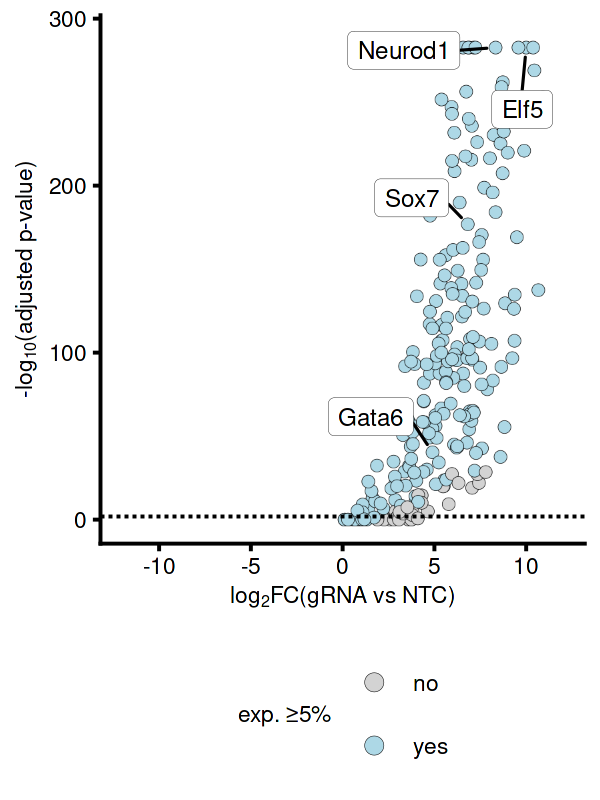

In [4]:
activate_df <- degs[degs$target == degs$gene,]

min_p <- min(activate_df[is.finite(-log10(activate_df$p_val_adj)) == TRUE, ]$p_val_adj)

activate_df$p_val_adj <- ifelse(is.finite(-log10(activate_df$p_val_adj)) == FALSE,min_p,activate_df$p_val_adj)

activate_df$pct.thresh <- ifelse(activate_df$pct.1 >= .05,"yes","no")


f1b <- ggplot(activate_df, aes(x=avg_log2FC,y=-log10(p_val_adj),fill=pct.thresh)) + 

       geom_point_rast(shape=21,color="black",size=2,stroke=.1) + 

       xlim(-1.1*max(degs[degs$target == degs$gene,]$avg_log2FC),
            1.1*max(degs[degs$target == degs$gene,]$avg_log2FC)) +
           theme_classic() +

           theme(axis.line = element_line(color = "black"),
            panel.grid = element_blank(),legend.position="bottom") + 

            xlab(bquote(log[2]*.("FC(gRNA vs NTC)"))) + 
            ylab(bquote("-"*log[10]*.("(adjusted p-value)"))) + 

            ggrepel::geom_label_repel(
              data = activate_df[activate_df$target %in% c("Gata6","Neurod1","Sox7","Elf5"),],
              aes(label = target),
              color = "black",
              nudge_y=5,
              nudge_x=-2,
              box.padding = 0.4,
              point.padding = 0.3,
              segment.color = "black",
              segment.size = 0.4,
              fill = "white",
              label.size = .05,
              min.segment.length = 0,
              force = 1,
              max.overlaps = Inf,
              size = 3) +
           scale_fill_manual(values=c("lightgrey","lightblue")) + 
           labs(fill="exp. ≥5%") + 
           guides(fill=guide_legend(nrow=2,override.aes = list(size=3))) + 
           geom_hline(yintercept=-log10(.01),linetype="dashed")+
  theme(
    text = element_text(size = 8),
    axis.title = element_text(size = 8),
    axis.text = element_text(size = 8),
    legend.title = element_text(size = 8),
    legend.text = element_text(size = 8)
  )

options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
f1b

### Figure 1C-F: UMAP characterization
First defining a version of lochNESS that works for gene expression:

In [5]:
exp_lochNESS <- function(obj, gene, umap_) {
    safe_column_scale = function(bmat, scale_vector) {
      bmat@x <- bmat@x / rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    safe_column_multiply = function(bmat, scale_vector) {
      bmat@x <- bmat@x * rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    kadj = round(0.5 * sqrt(ncol(obj)))

    exp.df <- as.data.frame(GetAssayData(object = obj, assay = "RNA", slot = "data")[gene, ])
    names(exp.df)[1] <- 'exp'

    obj@meta.data$genotype <- ifelse(rownames(obj@meta.data) %in% rownames(exp.df[exp.df$exp > 0,,drop=FALSE]), "KO", "WT")

    # MT scores
    mt_counts = as.data.frame(table(obj$genotype))
    mutant_mask = ifelse(obj@meta.data$genotype=="WT", 0, 1)

    mutant_neighbors = Matrix::rowSums(safe_column_multiply(obj@graphs$RNA_nn, mutant_mask))
    
    pca_mutant_score = (mutant_neighbors / kadj) / (1 - mt_counts$Freq[mt_counts$Var1=='WT'] / length(mutant_neighbors)) - 1

    # plotting
    mutant_score = pca_mutant_score
    df_umap = as.data.frame(obj[[umap_]]@cell.embeddings)

    df_umap$raw_mt_score = mutant_score
    # df_umap$mt_score = scale(mutant_score, center = TRUE, scale = FALSE)

    bg1 = df_umap[obj$genotype=="WT",]
    dt1 = df_umap[obj$genotype!="WT",]

    df_umap$genotype <- obj@meta.data$genotype[match(rownames(df_umap), rownames(obj@meta.data))]
    df_umap
}

Creating a single UMAP plot that shows the gene expression of Nanog (to mark pluripotent cells), Col1a1 (to mark fibroblast-like cells), Zscan4d (to mark 2C-like cells), Tfap2C (to mark trophectoderm-like cells) and Gcm1 (to mark trophoblast-like cells):

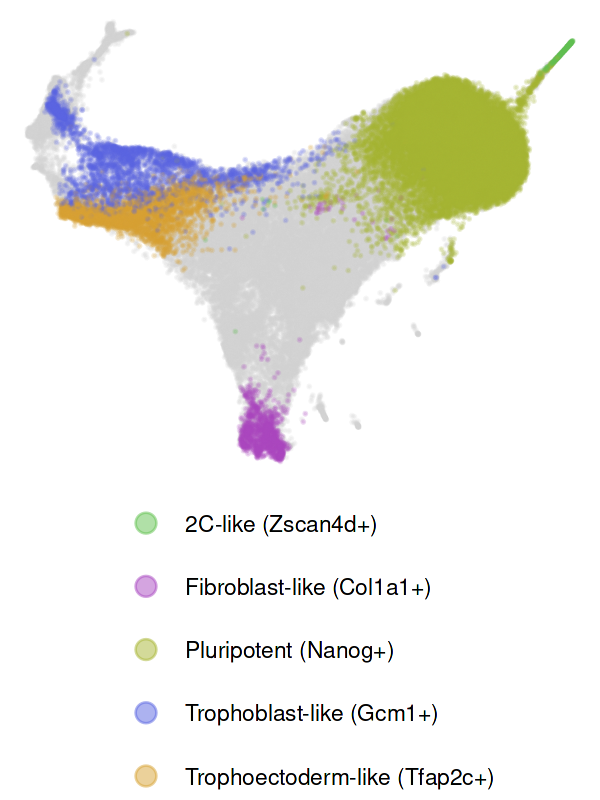

In [7]:
gene_annotations <- list("Nanog"="Pluripotent",
                         "Col1a1"="Fibroblast-like",
                         "Zscan4d"="2C-like",
                         "Tfap2c"="Trophoectoderm-like",
                         "Gcm1"="Trophoblast-like")


gene_cutoffs <- list("Nanog"=1,
                         "Col1a1"=1,
                         "Zscan4d"=1,
                         "Tfap2c"=3,
                         "Gcm1"=1)

umap_ <- "umapRNA"

UMAP.df <- as.data.frame(rna.obj[[umap_]]@cell.embeddings)
colnames(UMAP.df) <- c("UMAP1", "UMAP2")
UMAP.df$cells <- " "

for (gene in names(gene_annotations)) {
    
    cutoff <- gene_cutoffs[[gene]]
    annotation <- paste0(gene_annotations[[gene]]," (",gene,"+)")
    
    gene_loch <- exp_lochNESS(rna.obj, gene, "umapRNA")
    gene_loch <- gene_loch[gene_loch$genotype == "KO",]
        
    cells <- rownames(gene_loch[gene_loch$raw_mt_score > cutoff*mean(gene_loch$raw_mt_score),])

    UMAP.df$cells <- ifelse(rownames(UMAP.df) %in% cells, annotation,
                     ifelse(UMAP.df$cells != " ", UMAP.df$cells, " "))       
    
    }

c_ <- c("#62c251", "#aa4ac1", "#a8b635", "#5b66e1", "#d7a336", "#417eed", 
        "#d97f2e", "#9b67e1", "#47963c", "#cf43a8", "#54c79a", "#e44586", 
        "#317341", "#d980dd", "#5f7b2b", "#5553b7", "#8db870", "#a9519c", 
        "#409775", "#d34250", "#42c0c7", "#ce4c2b", "#4d85d5", "#beaa62", 
        "#8d82dd", "#79702a", "#7a559d", "#9c642e", "#56a7d9", "#e58e6e", 
        "#4769a2", "#ab544f", "#a19ee0", "#b2386a", "#cc8ec7", "#994f72", 
        "#e4819f")




f1c <- ggplot() +
 geom_point_rast(data = UMAP.df[UMAP.df$cells == " ",], aes(x=UMAP1,y=UMAP2),color="lightgrey",size=.1,alpha=.2) +
 geom_point_rast(data = UMAP.df[UMAP.df$cells != " ",], aes(x=UMAP1,y=UMAP2,color=cells),size=.1,alpha=.2) +
  theme_void() + 
   theme(
    legend.text = element_text(size = 8)
  ) +
 scale_color_manual(values=c_) +
 theme(
      plot.title = element_text(hjust = 0.5),legend.position="bottom") + 
 guides(color = guide_legend(nrow = 5, override.aes = list(size = 3,alpha=.5))) +
 labs(color = "")
options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
f1c

Showing distribution of Neurod1, Elf5, Gata6, and Sox7 gRNAs in UMAP space:

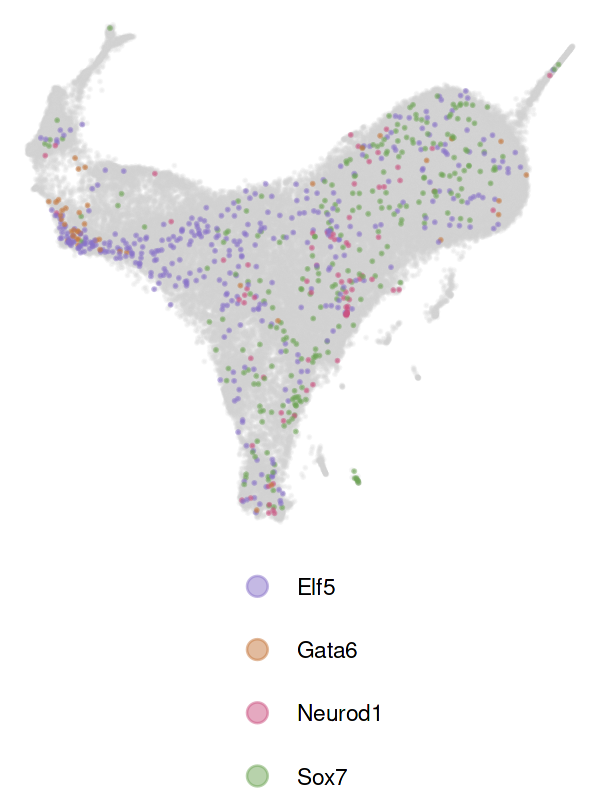

In [8]:
c_ <- c("#62c251", "#aa4ac1", "#a8b635", "#5b66e1", "#d7a336", "#417eed", 
        "#d97f2e", "#9b67e1", "#47963c", "#cf43a8", "#54c79a", "#e44586", 
        "#317341", "#d980dd", "#5f7b2b", "#5553b7", "#8db870", "#a9519c", 
        "#409775", "#d34250", "#42c0c7", "#ce4c2b", "#4d85d5", "#beaa62", 
        "#8d82dd", "#79702a", "#7a559d", "#9c642e", "#56a7d9", "#e58e6e", 
        "#4769a2", "#ab544f", "#a19ee0", "#b2386a", "#cc8ec7", "#994f72", 
        "#e4819f")

UMAP.df <- as.data.frame(rna.obj[["umapRNA"]]@cell.embeddings)
colnames(UMAP.df) <- c("UMAP1", "UMAP2")

tfs <- list("Neurod1" = "#cb5582", "Elf5" = "#8975ca", "Gata6" = "#c5783e", "Sox7" = "#71a659")

all.cells <- c()
for (tf in names(tfs)) {
  all.cells <- unique(c(all.cells, rownames(rna.obj@meta.data[grepl(tf, rna.obj@meta.data$target) == TRUE, ])))
}

UMAP.df$target <- ifelse(rownames(UMAP.df) %in% rownames(rna.obj@meta.data[grepl("Neurod1", rna.obj@meta.data$target) == TRUE, ]),"Neurod1",
                  ifelse(rownames(UMAP.df) %in% rownames(rna.obj@meta.data[grepl("Elf5", rna.obj@meta.data$target) == TRUE, ]),"Elf5",
                  ifelse(rownames(UMAP.df) %in% rownames(rna.obj@meta.data[grepl("Gata6", rna.obj@meta.data$target) == TRUE, ]),"Gata6",
                  ifelse(rownames(UMAP.df) %in% rownames(rna.obj@meta.data[grepl("Sox7", rna.obj@meta.data$target) == TRUE, ]),"Sox7",""))))

set.seed(1984)

f1d <- ggplot() + 
  geom_point_rast(data = UMAP.df[!(rownames(UMAP.df) %in% all.cells), ], 
             aes(x = UMAP1, y = UMAP2), color = "lightgrey", size = 0.1, alpha = .2) + 
  geom_point_rast(data = UMAP.df[(rownames(UMAP.df) %in% all.cells), ], 
             aes(x = UMAP1, y = UMAP2,color=target), , size = .1, alpha = .5) + 
 
  theme_void() + 
   theme(
    legend.text = element_text(size = 8)
  ) +
  scale_color_manual(values = tfs) +
  theme(plot.title = element_text(hjust = 0.5),legend.position="bottom") +
 guides(color = guide_legend(nrow = 4, override.aes = list(size = 3, alpha = .5))) +
 labs(color = "")

options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
f1d 

Showing expression of Elf5 in UMAP space:

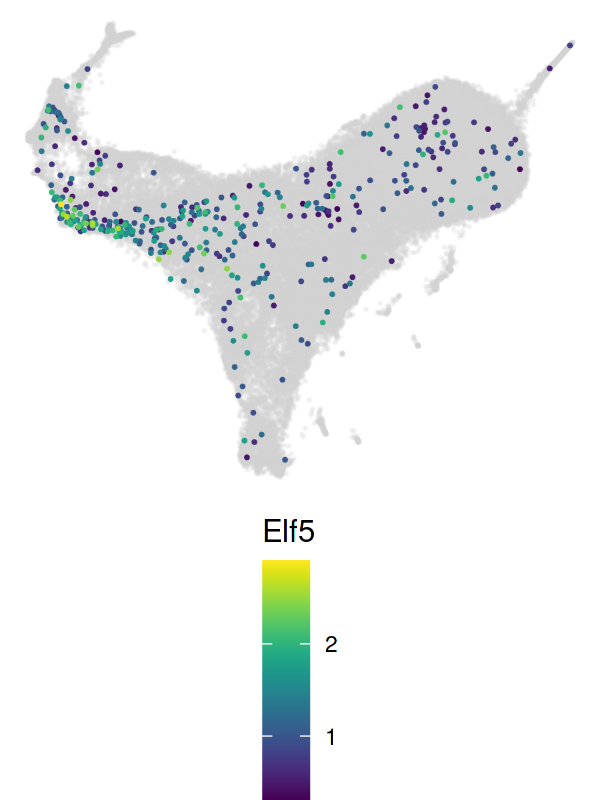

In [9]:
gene <- "Elf5"
umap_ <- "umapRNA"
x_label <- gene

# Creating a dataframe with the normalized counts of the gene of interest for each cell
exp.df <- as.data.frame(GetAssayData(object = rna.obj, assay = "RNA", slot = "data")[gene, ])
# Renaming the column
names(exp.df)[1] <- 'exp'
exp.df$CBC <- row.names(exp.df)

UMAP.df <- as.data.frame(rna.obj[[umap_]]@cell.embeddings)
colnames(UMAP.df) <- c("UMAP1", "UMAP2")
UMAP.df$CBC <- row.names(UMAP.df)

exp.df$UMAP1 <- UMAP.df$UMAP1[match(exp.df$CBC, UMAP.df$CBC)]
exp.df$UMAP2 <- UMAP.df$UMAP2[match(exp.df$CBC, UMAP.df$CBC)]
exp.df <- exp.df[order(exp.df$exp),]


f1e <- ggplot() +
 geom_point_rast(data = exp.df[exp.df$exp == 0,], aes(x=UMAP1,y=UMAP2),color="lightgrey",size=.1,alpha=.2) +
 geom_point_rast(data = exp.df[exp.df$exp > 0,], aes(x=UMAP1,y=UMAP2,color=exp),size=.1,alpha=1) +
 scale_color_viridis() +
 guides(color = guide_colorbar(direction = "vertical")) +
  theme_void() + 
   theme(
    legend.text = element_text(size = 8)
  ) +
 theme(legend.position="bottom",
      plot.title = element_text(hjust = 0.5)) +
 labs(color = x_label)
 
options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
f1e

Showing the distribution of NTC gRNAs in UMAP space:

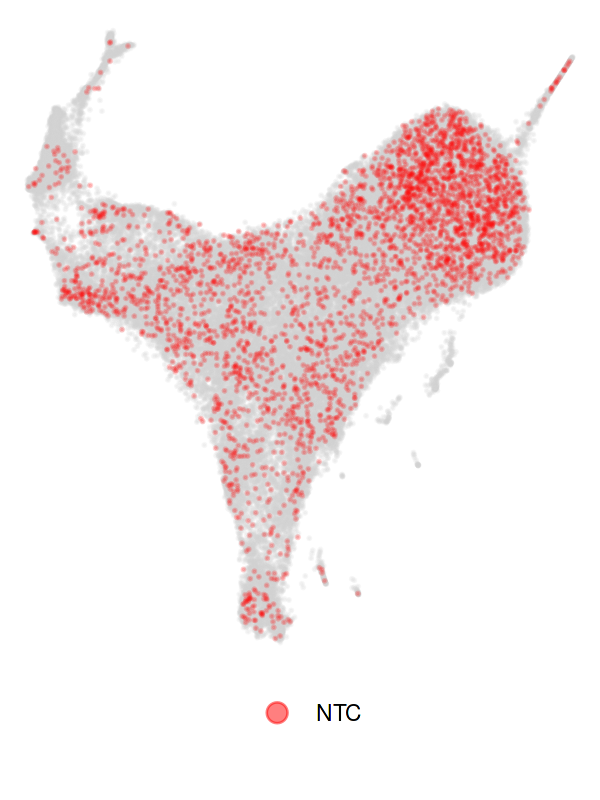

In [10]:
UMAP.df <- as.data.frame(rna.obj[["umapRNA"]]@cell.embeddings)
colnames(UMAP.df) <- c("UMAP1", "UMAP2")

tfs <- list("NTC" = "red")

UMAP.df$target <- ifelse(rownames(UMAP.df) %in% rownames(rna.obj@meta.data[rna.obj@meta.data$target == "NTC", ]),"NTC","")

set.seed(1984)
options(repr.plot.width=7, repr.plot.height=7, repr.plot.res=200)
f1f <- ggplot() + 
  geom_point_rast(data = UMAP.df[UMAP.df$target != "NTC", ], 
             aes(x = UMAP1, y = UMAP2), color = "lightgrey", size = 0.1, alpha = .2) + 
  geom_point_rast(data = UMAP.df[UMAP.df$target == "NTC", ], 
             aes(x = UMAP1, y = UMAP2,color=target), , size = .1, alpha = .2) + 

  theme_void() + 
   theme(
    legend.text = element_text(size = 8)
  ) +
  scale_color_manual(values=tfs) +
  theme(plot.title = element_text(hjust = 0.5),legend.position="bottom") +
 guides(color = guide_legend(nrow = 2, override.aes = list(size = 3, alpha = .5))) +
 labs(color = "") 


options(repr.plot.width=3, repr.plot.height=4, repr.plot.res=200)
f1f

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <a5>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'exp. ≥5%' in 'mbcsToSbcs': dot substituted for <a5>"
Warning message in grid.Call.graphics(C_text, 

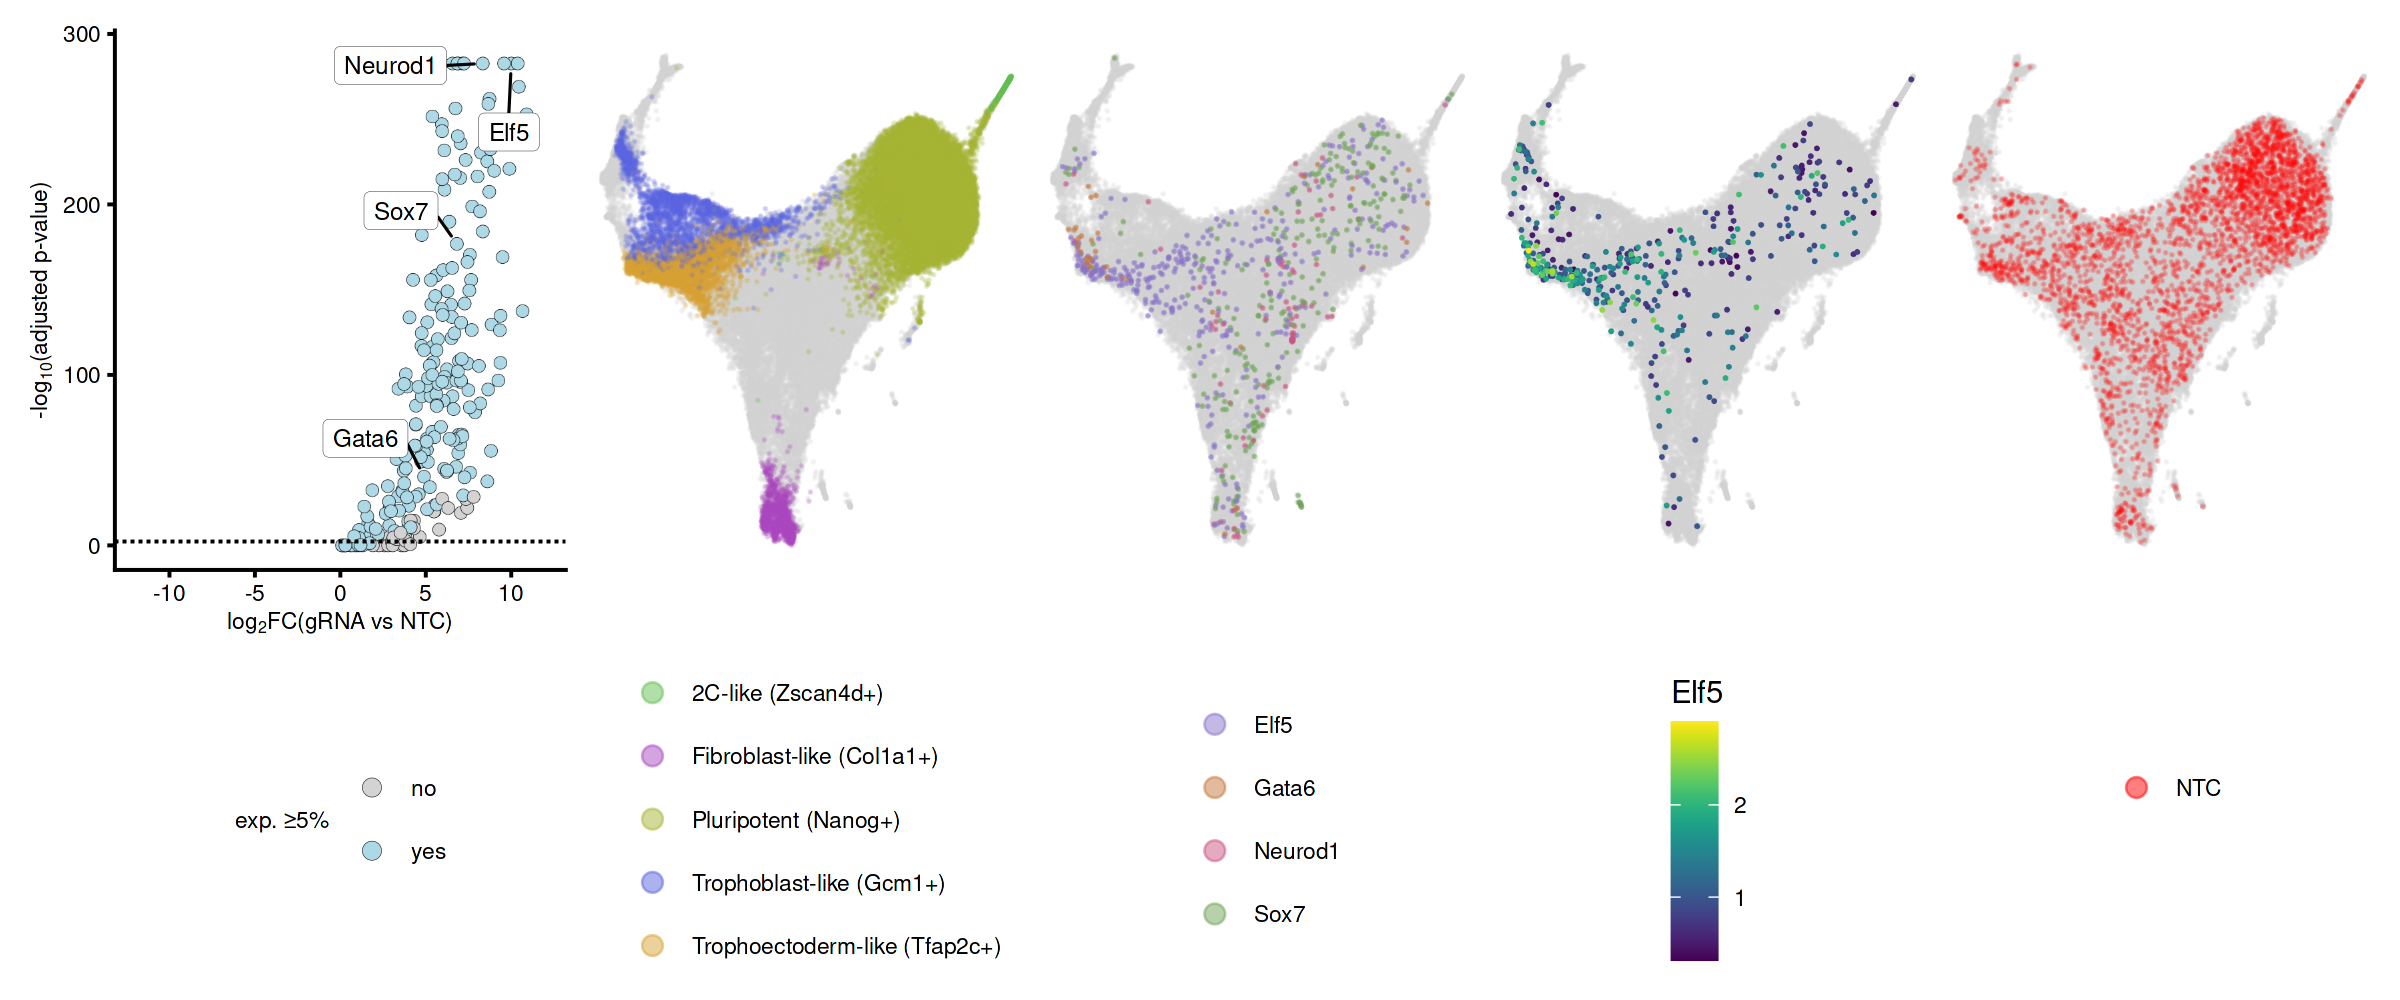

In [11]:
layout <- "ABCDE"

fig1b_f <- f1b + f1c +f1d + f1e + f1f +
  plot_layout(design = layout)


options(repr.plot.width=12, repr.plot.height=5, repr.plot.res=200)
fig1b_f

### Figure 1G: Number of differentially expressed genes per TF

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥100' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥100' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥100' in 'mbcsToSbcs': dot substituted for <a5>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥100' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥100' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥100' in 'mbcsToSbcs': dot substituted for <a5>"


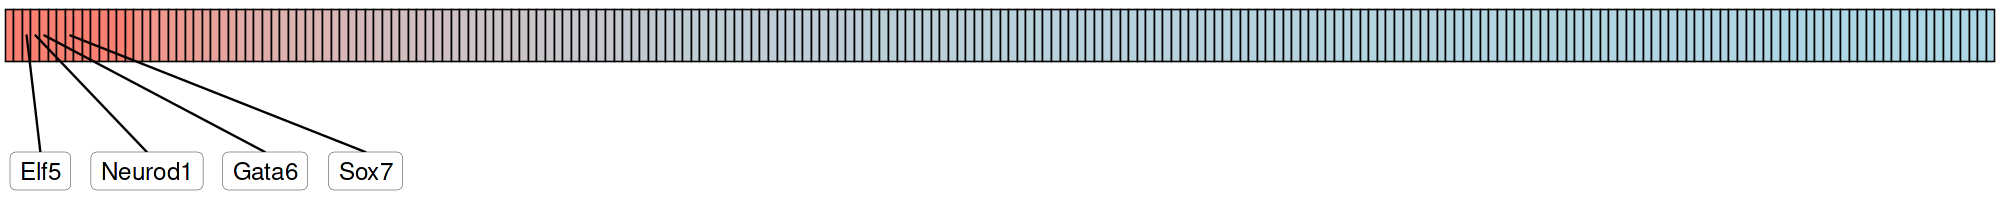

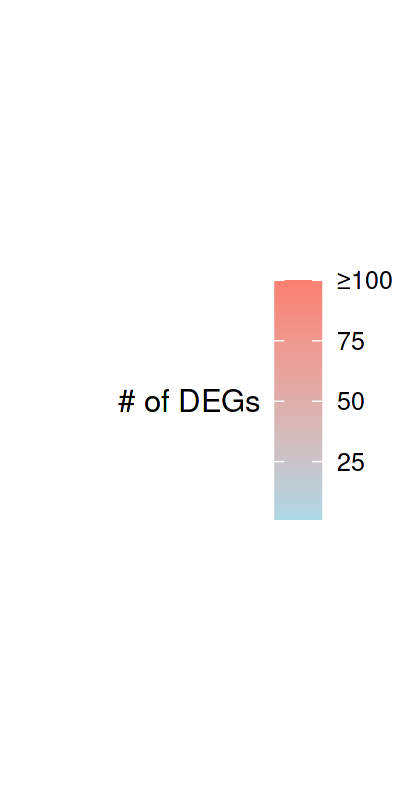

In [12]:
deg_count <- as.data.frame(table(degs[degs$p_val_adj <= .01 & 
                                           degs$avg_log2FC >= log2(1.2) &
                                      degs$pct.1 >= .05,]$target))

deg_count <- deg_count[order(-deg_count$Freq),]
colnames(deg_count) <- c("tf","n_DEGs")
deg_count$lab=0
deg_count$tf <- factor(deg_count$tf, levels = deg_count$tf[order(-deg_count$n_DEGs)])

deg_count$n_DEGs <- ifelse(deg_count$n_DEGs >= 100,100,deg_count$n_DEGs)



show_labels <- c("Neurod1", "Sox7", "Elf5","Gata6")


label_map <- setNames(ifelse(levels(deg_count$tf) %in% show_labels, 
                             levels(deg_count$tf), ""), 
                      levels(deg_count$tf))

deg_count$num <- 1:nrow(deg_count)


f1g <- ggplot(deg_count, aes(x = num, y = lab, fill = n_DEGs)) + 
  geom_tile(aes(y = 0),color = "black") + 
  scale_fill_gradient(
    low = "lightblue",
    high = "salmon",  
    labels = function(x) ifelse(x == 100, "≥100", x)
  ) +
  scale_x_discrete(labels = c()) +
  theme_void() +
  theme(axis.text.x = element_text(angle = 45, hjust = 2),
        legend.position="none")  + 
  xlab("") + ylab("") + 
  geom_label_repel(
    data = subset(deg_count, tf %in% show_labels),
    aes(x = num, y = 0, label = tf),  # anchor point at tile
    nudge_y = -3,                      # move label above
    direction = "x",                  # repel along x-axis
    segment.size = 0.3,
    segment.color = "black",
    size = 3,
    force = 1,
    label.size = .05,
    max.overlaps = Inf,fill="white"
  )

f1g.l <- ggplot(deg_count, aes(x = tf, y = lab, fill = n_DEGs)) + 
  geom_tile(alpha=0) + 
  scale_fill_gradient(
    low = "lightblue",
    high = "salmon",
    labels = function(x) ifelse(x == 100, "≥100", x)
  ) +
  scale_x_discrete(labels = label_map) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),
        legend.position="none",
           legend.title = element_text(size = 8),
    legend.text = element_text(size = 8))  + 
  xlab("") + ylab("") + 
  guides(fill = guide_colorbar(title.position = "left")) +
  theme_void() + labs(fill="# of DEGs")


options(repr.plot.width = 10, repr.plot.height = 1, repr.plot.res = 200)
f1g
options(repr.plot.width = 2, repr.plot.height = 4, repr.plot.res = 200)
f1g.l

In [13]:
deg_count <- as.data.frame(matrix(ncol=0,nrow=0))
for (tf in rna.targets[2:length(rna.targets)]) {
    
    n_tf_deg <- nrow(degs[degs$target == tf &
                   degs$p_val_adj <= .01 & 
                   degs$avg_log2FC >= log2(1.2) &
                   degs$pct.1 >= .05,])
   deg_count <-  rbind(deg_count,c(tf,n_tf_deg)) 
    
}



colnames(deg_count) <- c("tf","n_DEGs")
deg_count$n_DEGs <- as.numeric(deg_count$n_DEGs)

deg_count <- deg_count[order(-deg_count$n_DEGs),]

cat(sprintf("Range of DEGs per TF: %d - %d\n",
            min(deg_count$n_DEGs), max(deg_count$n_DEGs)))

cat(sprintf("Median DEGs per TF: %.1f\n",
            median(deg_count$n_DEGs)))

q <- quantile(deg_count$n_DEGs, probs = c(0.25, 0.75))
cat(sprintf("IQR of DEGs per TF: %.1f (Q1 = %.1f, Q3 = %.1f)\n",
            IQR(deg_count$n_DEGs), q[1], q[2]))

cat(sprintf("Median nFeature_RNA per cell: %.0f\n",
            median(rna.obj@meta.data$nFeature_RNA)))

Range of DEGs per TF: 0 - 394
Median DEGs per TF: 10.0
IQR of DEGs per TF: 21.8 (Q1 = 4.0, Q3 = 25.8)
Median nFeature_RNA per cell: 2765


200

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the enrichplot package.
  Please report the issue at <https://github.com/GuangchuangYu/enrichplot/issues>."
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


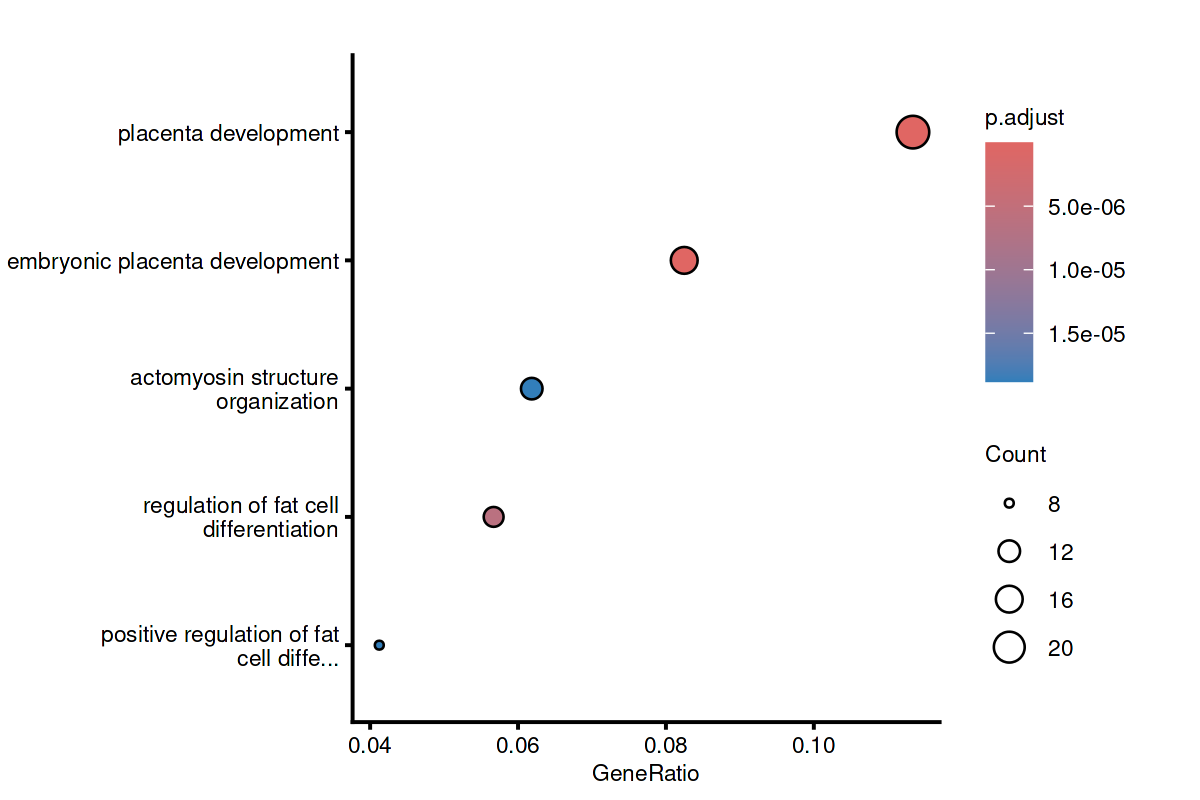

In [14]:
tf <- "Elf5"

tf.deg <- degs[degs$target == tf,]

tf.deg <- tf.deg[order(-tf.deg$avg_log2FC),]


library(clusterProfiler)
library(org.Mm.eg.db)

# 1. pull out the top 200 mouse‐symbol DE genes
elf5_degs <- tf.deg[
    tf.deg$pct.1 >= 0.05 &
    tf.deg$p_val_adj < 0.01 &
    tf.deg$avg_log2FC >= log2(1.2),
]

elf5_degs <- elf5_degs[order(elf5_degs$avg_log2FC, decreasing = TRUE), ]

top100_mouse <- head(elf5_degs$gene, 200)


message(length(top100_mouse))

# 2. run GO‐BP enrichment for mouse
ego_mouse <- enrichGO(
  gene          = top100_mouse,
  OrgDb         = org.Mm.eg.db,
  keyType       = "SYMBOL",
  ont           = "BP",            # Biological Process
  pAdjustMethod = "BH",
  pvalueCutoff  = 0.05,
  qvalueCutoff  = 0.10
)

# Subset the enrichResult object using the top 10 IDs
top10_ids <- ego_mouse@result$ID[1:10]
ego_top10 <- ego_mouse
ego_top10@result <- ego_mouse@result[ego_mouse@result$ID %in% top10_ids, ]

# Optional: remove line breaks from descriptions
ego_top10@result$Description <- gsub("\n", " ", ego_top10@result$Description)



ego_top10@result$Description <- ifelse(
  nchar(ego_top10@result$Description) > 40,

  paste0(substr(ego_top10@result$Description, 1, 37), "..."),

  ego_top10@result$Description

)


f1h <- dotplot(ego_top10, showCategory = 5) + 
  scale_size(range = c(1, 5)) +
  theme_classic() +
  theme(
    text = element_text(size = 8),
    axis.title = element_text(size = 8),
    axis.text = element_text(size = 8),
    legend.title = element_text(size = 8),
    legend.text = element_text(size = 8),
    axis.text.y = element_text(size = 8, hjust = 1),
    plot.margin = margin(5, 20, 5, 5)
  )
options(repr.plot.width=6, repr.plot.height=4, repr.plot.res=200)
f1h

### Showing lochNESS (PCA-based) and Moran's I (UMAP-based) nominate similar lists of 60 TFs
Creating a function to perform lochNESS on the 240 TF RNA data. Takes as input the single cell dataset, the TF or gRNA sequence of interest, and whether you want to perform lochNESS at the level of target TFs ("target") or individual gRNA sequences ("gRNAs"). 

In [15]:
rna_lochNESS <- function(obj, tf,type) {
    safe_column_scale = function(bmat, scale_vector) {
      bmat@x <- bmat@x / rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    safe_column_multiply = function(bmat, scale_vector) {
      bmat@x <- bmat@x * rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    kadj = round(0.5 * sqrt(ncol(obj)))
    
    ntc.guides <- unique(obj@meta.data[obj@meta.data$target == "NTC",]$gRNAs)
    
    # lochness
    # adding a "genotype" column that is "KO" for cbcs assigned a given gRNA,
    # and "WT" for all other cells
    if (type == "gRNAs" && tf %in% ntc.guides) {
        obj@meta.data$genotype <- ifelse(obj@meta.data$gRNAs == tf, "KO", "WT")
    } else if (type == "target" && tf == "NTC") {
        obj@meta.data$genotype <- ifelse(obj@meta.data$target == "NTC", "KO", "WT")
    } else {
        obj@meta.data$genotype <- ifelse(grepl(paste0('(^|_)', tf, '(_|$)'), obj@meta.data[[type]]) == TRUE, "KO", "WT")
    }

    # MT scores
    mt_counts = as.data.frame(table(obj$genotype))
    mutant_mask = ifelse(obj@meta.data$genotype=="WT", 0, 1)
    mutant_neighbors = Matrix::rowSums(safe_column_multiply(obj@graphs$RNA_nn, mutant_mask))
    
    
    pca_mutant_score = (mutant_neighbors / kadj) / (1 - mt_counts$Freq[mt_counts$Var1=='WT'] / length(mutant_neighbors)) - 1

    # plotting
    mutant_score = pca_mutant_score
    df_umap = as.data.frame(obj[['umapRNA']]@cell.embeddings)

    df_umap$raw_mt_score = mutant_score
    # df_umap$mt_score = scale(mutant_score, center = TRUE, scale = FALSE)

    bg1 = df_umap[obj$genotype=="WT",]
    dt1 = df_umap[obj$genotype!="WT",]
    
    df_umap$genotype <- obj@meta.data$genotype[match(rownames(df_umap), rownames(obj@meta.data))]
    df_umap
}

Running lochNESS on all target TFs and recording the mean, median and max lochNESS score. Also recording the mean, median, and max lochNESS score normalized by cell number (simply multiplying by the number of cells)

In [16]:
loch_stats <- as.data.frame(matrix(ncol=0,nrow=0))
for (tf in c(rna.targets[2:length(rna.targets)],"NTC")) {

    message(tf)
    n.cells <- length(rownames(rna.obj@meta.data[grepl(tf,rna.obj@meta.data$target) == TRUE,]))
    loch <- rna_lochNESS(rna.obj,tf,"target")
    loch$normalized_score <- (loch$raw_mt_score / n.cells)

    mean_ <- mean(loch[loch$genotype == "KO",]$raw_mt_score)
    median_ <- median(loch[loch$genotype == "KO",]$raw_mt_score)
    max_ <- max(loch[loch$genotype == "KO",]$raw_mt_score)

    mean_norm <- mean(loch[loch$genotype == "KO",]$raw_mt_score) * n.cells
    median_norm <- median(loch[loch$genotype == "KO",]$raw_mt_score) * n.cells
    max_norm <- max(loch[loch$genotype == "KO",]$raw_mt_score) * n.cells

    loch_stats <- rbind(loch_stats,c(tf,n.cells,mean_,median_,max_,mean_norm,median_norm,max_norm))

    }

colnames(loch_stats) <- c("tf","n.cells","mean","median","max","normalized_mean","normalized_median","normalized_max")
loch_stats[, 2:ncol(loch_stats)] <- lapply(loch_stats[, 2:ncol(loch_stats)],as.numeric)

Alx1

Alx3

Alx4

Ar

Arx

Ascl1

Barhl1

Barhl2

Batf3

Bcl11a

Bcl6b

Bhlhe23

Bhlhe41

Cdx2

Cdx4

Crem

Dlx1

Dlx2

Dlx3

Dlx5

Dlx6

Dmbx1

Ebf2

Ebf3

Elf5

Emx1

Emx2

En1

Eomes

Erg

Esr1

Esr2

Esrrb

Esrrg

Ets1

Etv1

Etv2

Evx1

Evx2

Fev

Fli1

Fosl1

Foxa1

Foxa2

Foxb1

Foxc1

Foxc2

Foxf1

Foxf2

Foxg1

Foxl2

Foxp1

Foxp2

Foxq1

Gata1

Gata3

Gata5

Gata6

Gbx1

Gfi1

Gfi1b

Glis1

Grhl1

Hand1

Hand2

Hes7

Hey2

Hic1

Hlf

Hmx1

Hmx2

Hmx3

Hnf1b

Hnf4a

Hoxa10

Hoxa2

Hoxa4

Hoxa6

Hoxa9

Hoxb2

Hoxb3

Hoxb4

Hoxb5

Hoxb6

Hoxb7

Hoxb8

Hoxc10

Hoxc8

Hoxc9

Hoxd3

Ikzf1

Insm1

Irf1

Irf2

Irf5

Irf7

Isl1

Isl2

Jdp2

Klf1

Klf12

Klf14

Lbx1

Lef1

Lhx1

Lhx3

Lhx4

Lhx5

Lhx6

Lhx8

Lhx9

Lmx1a

Lmx1b

Maf

Mafb

Mecom

Mef2c

Meis1

Meis2

Meis3

Meox1

Meox2

Mitf

Mixl1

Msx1

Mxi1

Myb

Myod1

Myog

Neurod1

Neurog1

Neurog2

Nfatc1

Nfe2

Nfia

Nfib

Nfix

Nhlh1

Nhlh2

Nkx2-1

Nkx2-3

Nkx2-5

Nkx6-1

Noto

Npas2

Npas4

Nr2e1

Nr2f1

Nr2f2

Nr3c2

Nr4a2


Reading in Moran's I results:

In [17]:
load_moransI_gRNA <- function(sample) {
    result <- readRDS(file = paste0("../figure_data/240-TF_MoransI_", sample, ".rds"))
    result$gRNAs <- row.names(result)
    result$target <- as.data.frame(colData(rna.240))$target[match(result$gRNAs, as.data.frame(colData(rna.240))$gRNAs)]
    result$rank <- 1:nrow(result)
    result
}

gRNA_K500 <- load_moransI_gRNA("gRNA_K500")

Finding a q-value cutoff that only 5% of NTC values pass (5% FDR):

In [18]:
# Sort all q-values from lowest to highest
sorted_q <- sort(gRNA_K500$q_value)

# Total number of NTCs
n_ntc_total <- sum(gRNA_K500$target == "NTC")

# Fraction of NTCs passing each cutoff
fdr_vals <- sapply(sorted_q, function(cutoff) {
  n_ntc_pass <- sum(gRNA_K500$target == "NTC" &
                    gRNA_K500$q_value <= cutoff)

  n_ntc_pass / n_ntc_total
})

# Largest q-value where <=5% of NTCs pass
q_cutoff <- max(sorted_q[fdr_vals <= 0.05], na.rm = TRUE)

# Annotate passing rows
gRNA_K500$pass_FDR <- gRNA_K500$q_value <= q_cutoff

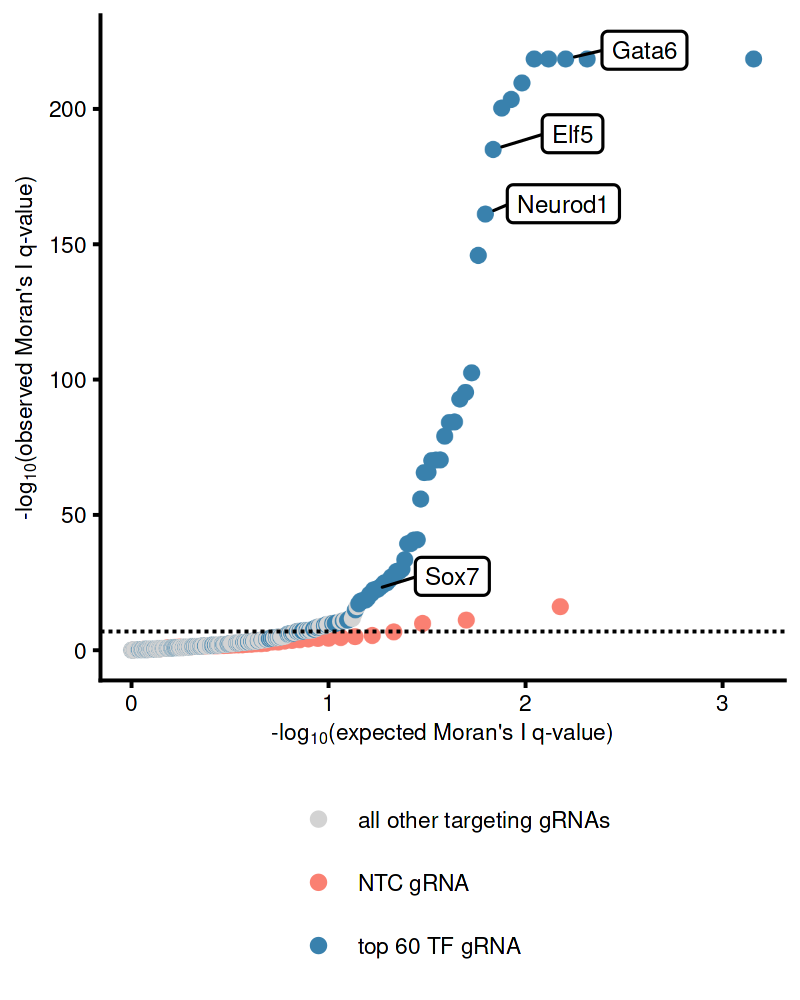

In [19]:
library(dplyr)
library(ggplot2)

# Define three color classes
targets <- read.table("../figure_data/targets.tsv", sep = "\t", header = FALSE)$V1
df <- gRNA_K500 %>%
  mutate(
    type = ifelse(
      target == "NTC", "NTC gRNA",
      ifelse(target %in% targets, "top 60 TF gRNA", "all other targeting gRNAs")
    ),
    qq_group = ifelse(target == "NTC", "NTC", "targeting"),
    observed = -log10(q_value)
  )

# Compute expected quantiles for Exp(rate = log(10)) *within each qq_group*
qq_df <- df %>%
  group_by(qq_group) %>%
  arrange(observed, .by_group = TRUE) %>%
  mutate(
    n = n(),
    p = ppoints(n),                         # (i - 0.5) / n
    expected = qexp(p, rate = log(10))
  ) %>%
  ungroup()

cols <- c(
  "NTC gRNA"                  = "salmon",
  "top 60 TF gRNA"            = "#3981ad",
  "all other targeting gRNAs" = "lightgrey"
)


gRNAs_viz <- c()

for (tf in c("Elf5","Gata6","Neurod1","Sox7")) {
    sub_qq <- qq_df[qq_df$target == tf,]
    gRNAs_viz <- c(gRNAs_viz,sub_qq[sub_qq$q_value == min(sub_qq$q_value),]$gRNAs)
}

max_real <- max(qq_df$observed[is.finite(qq_df$observed)], na.rm = TRUE)
qq_df$observed <- ifelse(is.infinite(qq_df$observed), max_real, qq_df$observed)


f1i <- ggplot(qq_df, aes(x = expected, y = observed, color = type)) +
  geom_point_rast(size = 2) +
  scale_color_manual(values = cols, drop = FALSE) +
  theme_classic() +
  theme(text = element_text(size = 8),
    axis.title = element_text(size = 8),
    axis.text = element_text(size = 8),
    legend.title = element_text(size = 8),
    legend.text = element_text(size = 8), legend.position = "bottom") +
  geom_hline(yintercept = -log10(q_cutoff), linetype = "dashed") +
  ylab(bquote("-"*log[10]*.("(observed Moran's I q-value)"))) +
  xlab(bquote("-"*log[10]*.("(expected Moran's I q-value)"))) +
  labs(color = "") +
  guides(color = guide_legend(nrow = 3))

f1i <- f1i + ggrepel::geom_label_repel(
              data = subset(qq_df, gRNAs %in% gRNAs_viz),
              aes(label = target),
              color = "black",
              nudge_y=5,
              nudge_x=0.4,
              box.padding = 0.4,
              point.padding = 0.3,
              segment.color = "black",
              segment.size = 0.4,
              fill = "white",
              label.size = .4,
              min.segment.length = 0,
              force = 1,
              max.overlaps = Inf,
              size = 3
            ) 
options(repr.plot.width = 4, repr.plot.height = 5, repr.plot.res = 200)
f1i


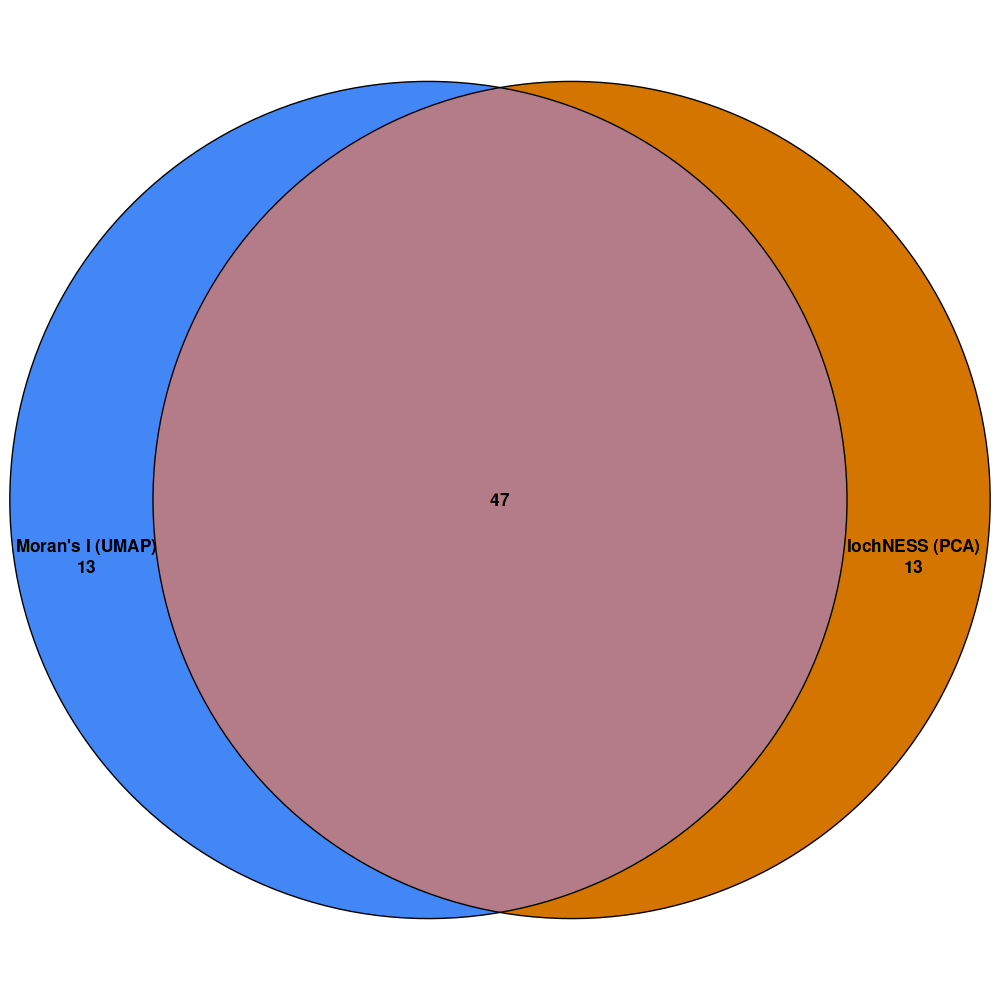

In [20]:
lochness.targets <- head(loch_stats[order(-loch_stats$normalized_mean),]$tf, 60)

venn_fit <- euler(c(
    "Moran's I (UMAP)" = length(setdiff(targets, lochness.targets)),
    "lochNESS (PCA)" = length(setdiff(lochness.targets, targets)),
    "Moran's I (UMAP)&lochNESS (PCA)" = length(intersect(targets, lochness.targets))
))

f1j <- plot(
    venn_fit,
    quantities = list(font = 2),
    labels = list(font = 2, padding = -0.5),
    fills = c("#4287f5", "#d47500"),
    edges = list(col = "black", lwd = 1)
)

options(repr.plot.width = 10, repr.plot.height = 10, repr.plot.res = 100)
f1j

In [21]:
# ============================================================
# Summary statistics for manuscript
# ============================================================

# Target-TF activation statistics
activate_df <- degs[degs$target == degs$gene & degs$target != "NTC", ]

# Same significance/expression criteria used in Fig. 1
activated <- activate_df[
    activate_df$p_val_adj <= 0.01 &
    activate_df$avg_log2FC > 0 &
    activate_df$pct.1 >= 0.05,
]

cat("TARGET TF ACTIVATION\n")
cat("--------------------\n")
cat("Total TFs:", nrow(activate_df), "\n")
cat("Significantly activated:", nrow(activated), "\n")
cat(
    "Percent significantly activated:",
    round(100 * nrow(activated) / nrow(activate_df), 1),
    "%\n"
)

# Maximum activation
max_idx <- which.max(activate_df$avg_log2FC)

cat(
    "Maximum log2FC:",
    activate_df$avg_log2FC[max_idx],
    "\n"
)
cat(
    "Maximum fold-change:",
    2^activate_df$avg_log2FC[max_idx],
    "\n"
)
cat(
    "TF with maximum activation:",
    activate_df$target[max_idx],
    "\n\n"
)


# ============================================================
# Number of DEGs per TF
# Same thresholds used for Fig. 1G
# ============================================================

sig_degs <- degs[
    degs$target != "NTC" &
    degs$p_val_adj <= 0.01 &
    degs$avg_log2FC >= log2(1.2) &
    degs$pct.1 >= 0.05,
]

# Include TFs with zero DEGs
deg_counts <- table(factor(
    sig_degs$target,
    levels = unique(activate_df$target)
))

cat("DIFFERENTIALLY EXPRESSED GENES\n")
cat("------------------------------\n")
cat("Minimum DEGs per TF:", min(deg_counts), "\n")
cat("Maximum DEGs per TF:", max(deg_counts), "\n")
cat("Median DEGs per TF:", median(deg_counts), "\n")
cat("Mean DEGs per TF:", mean(deg_counts), "\n")
cat("TFs with >=1 DEG:", sum(deg_counts > 0), "\n")
cat(
    "Percent TFs with >=1 DEG:",
    round(100 * mean(deg_counts > 0), 1),
    "%\n"
)

# TFs defining min/max, useful for sanity checking
cat("\nTF(s) with maximum # DEGs:\n")
print(names(deg_counts)[deg_counts == max(deg_counts)])

cat("\nTF(s) with zero DEGs:\n")
print(names(deg_counts)[deg_counts == 0])

TARGET TF ACTIVATION
--------------------
Total TFs: 237 
Significantly activated: 192 
Percent significantly activated: 81 %
Maximum log2FC: 10.90402 
Maximum fold-change: 1916.184 
TF with maximum activation: Hoxb6 

DIFFERENTIALLY EXPRESSED GENES
------------------------------
Minimum DEGs per TF: 0 
Maximum DEGs per TF: 394 
Median DEGs per TF: 10 
Mean DEGs per TF: 26.39662 
TFs with >=1 DEG: 230 
Percent TFs with >=1 DEG: 97 %

TF(s) with maximum # DEGs:
[1] "Cdx2"

TF(s) with zero DEGs:
[1] "Npas2"  "Pou2f1" "Pou3f3" "Pou6f2" "Scrt2"  "Sp4"    "Tfec"  


In [22]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] ggrastr_1.0.2                      eulerr_7.0.2                      
 [3] monocle3_1.3.5                     SingleCellExperiment_1